In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Iris.csv")

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [2]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (150, 6)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 9.1 KB
None

Missing Values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Duplicate Rows: 0


In [3]:
X = df.drop(["Id", "Species"], axis=1)
y = df["Species"]

print("Features:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(y.unique())

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

Features:
['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']

Target Classes:
<ArrowStringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str

Feature Shape: (150, 4)
Target Shape: (150,)


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

print("Normalized Features:")
print(X_scaled.head())

Normalized Features:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0      -0.900681      1.032057      -1.341272     -1.312977
1      -1.143017     -0.124958      -1.341272     -1.312977
2      -1.385353      0.337848      -1.398138     -1.312977
3      -1.506521      0.106445      -1.284407     -1.312977
4      -1.021849      1.263460      -1.341272     -1.312977


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (120, 4)
Testing Features Shape: (30, 4)
Training Target Shape: (120,)
Testing Target Shape: (30,)


In [8]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

print("KNN model trained successfully.")

KNN model trained successfully.


In [9]:
from sklearn.metrics import accuracy_score

y_pred = knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("KNN Accuracy:", accuracy)

KNN Accuracy: 0.9333333333333333


In [10]:
k_values = [1, 3, 5, 7, 9, 11, 13, 15]

k_accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    
    predictions = model.predict(X_test)
    acc = accuracy_score(y_test, predictions)
    
    k_accuracies.append(acc)

print("K Value | Accuracy")
print("-" * 25)

for k, acc in zip(k_values, k_accuracies):
    print(f"{k:7} | {acc:.4f}")

K Value | Accuracy
-------------------------
      1 | 0.9667
      3 | 0.9333
      5 | 0.9333
      7 | 0.9667
      9 | 0.9667
     11 | 0.9667
     13 | 0.9667
     15 | 0.9333


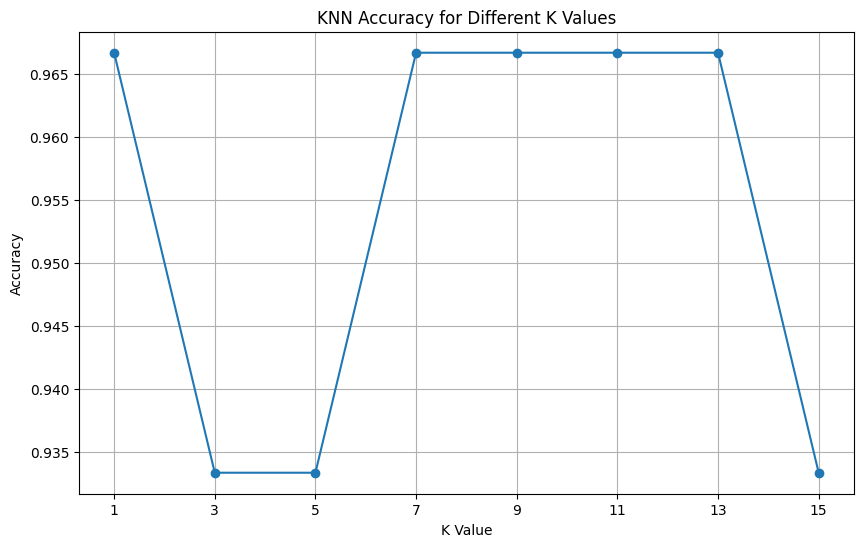

In [12]:
plt.figure(figsize=(10, 6))

plt.plot(k_values, k_accuracies, marker="o")

plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for Different K Values")
plt.xticks(k_values)
plt.grid()

plt.show()

In [13]:
final_knn = KNeighborsClassifier(n_neighbors=7)

final_knn.fit(X_train, y_train)

y_pred_final = final_knn.predict(X_test)

print("Final KNN Accuracy:", accuracy_score(y_test, y_pred_final))

Final KNN Accuracy: 0.9666666666666667


Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]


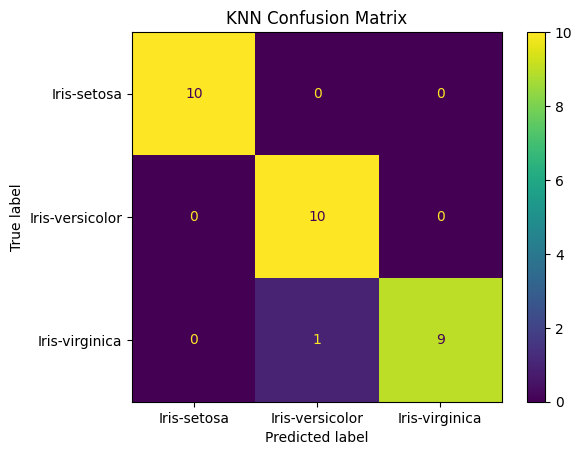

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_final)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=final_knn.classes_
)

disp.plot()
plt.title("KNN Confusion Matrix")
plt.show()

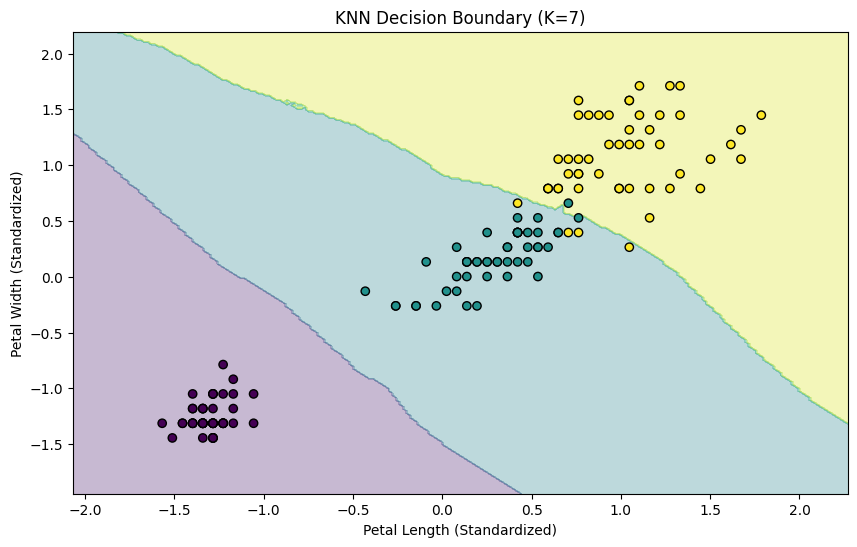

In [16]:
from sklearn.preprocessing import LabelEncoder

# Select two features for 2D visualization
X_2d = X_scaled[["PetalLengthCm", "PetalWidthCm"]]

# Encode species labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Train-test split for 2D data
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Train KNN model
knn_2d = KNeighborsClassifier(n_neighbors=7)
knn_2d.fit(X_train_2d, y_train_2d)

# Create mesh grid
x_min = X_2d["PetalLengthCm"].min() - 0.5
x_max = X_2d["PetalLengthCm"].max() + 0.5
y_min = X_2d["PetalWidthCm"].min() - 0.5
y_max = X_2d["PetalWidthCm"].max() + 0.5

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

# Convert grid points into DataFrame with feature names
grid_points = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=["PetalLengthCm", "PetalWidthCm"]
)

# Predict classes for each grid point
Z = knn_2d.predict(grid_points)
Z = Z.reshape(xx.shape)

# Plot decision boundaries
plt.figure(figsize=(10, 6))

plt.contourf(xx, yy, Z, alpha=0.3)

plt.scatter(
    X_2d["PetalLengthCm"],
    X_2d["PetalWidthCm"],
    c=y_encoded,
    edgecolors="k"
)

plt.xlabel("Petal Length (Standardized)")
plt.ylabel("Petal Width (Standardized)")
plt.title("KNN Decision Boundary (K=7)")

plt.show()

## Conclusion

K-Nearest Neighbors (KNN) classification was successfully implemented on the Iris dataset.

The features were standardized before training so that all measurements were on a comparable scale. Different values of K were tested, and K=7 was selected for the final model.

The final KNN model achieved an accuracy of 96.67% on the test dataset. The confusion matrix showed that 29 out of 30 test samples were classified correctly.

The decision boundary visualization using Petal Length and Petal Width showed how KNN separates the three Iris species based on their feature values.

Overall, KNN performed well on the Iris classification problem.